# Extra Analysis — Phase 1

Standalone companion to `Modeling.ipynb` (untouched). Run top-to-bottom.
**Part 1**: dataset visualizations (figs 25–30). **Part 2**: model visualizations (figs 18–24).

---
# Part 1 — Dataset visualizations


# Extra Dataset Deep-Dive (standalone)

Companion to `Modeling.ipynb` (untouched) and `Extra_Visuals.ipynb` (untouched). Raw-data EDA only — no modeling.

Reads `../last/Datasets/*.csv` (read-only) + `results/phase1_results/phase1_results.json`, writes:

`figures/phase1/25_dataset_cartography.png` … `30_calendar_windows.png`

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
RES = 'results/phase1_results'
FIG = 'figures/phase1'
os.makedirs(FIG, exist_ok=True)
DATA = '../last/Datasets' if os.path.isdir('../last/Datasets') else 'Datasets'
R = json.load(open(f'{RES}/phase1_results.json'))
MD = [f'MarkDown{i}' for i in range(1, 6)]

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    print('saved', f'{FIG}/{name}.png')

tr = pd.read_csv(f'{DATA}/train.csv', parse_dates=['Date'])
fe = pd.read_csv(f'{DATA}/features.csv', parse_dates=['Date'])
st = pd.read_csv(f'{DATA}/stores.csv')
te = pd.read_csv(f'{DATA}/test.csv', parse_dates=['Date'])
df = tr.merge(fe.drop(columns=['IsHoliday']), on=['Store', 'Date'], how='left').merge(st, on='Store', how='left')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
print('train', tr.shape, '| features', fe.shape, '| stores', st.shape, '| test', te.shape, '| merged', df.shape)
print('train dates:', tr['Date'].min().date(), '->', tr['Date'].max().date(), '| test dates:', te['Date'].min().date(), '->', te['Date'].max().date())


train (421570, 5) | features (8190, 12) | stores (45, 3) | test (115064, 4) | merged (421570, 19)
train dates: 2010-02-05 -> 2012-10-26 | test dates: 2012-11-02 -> 2013-07-26


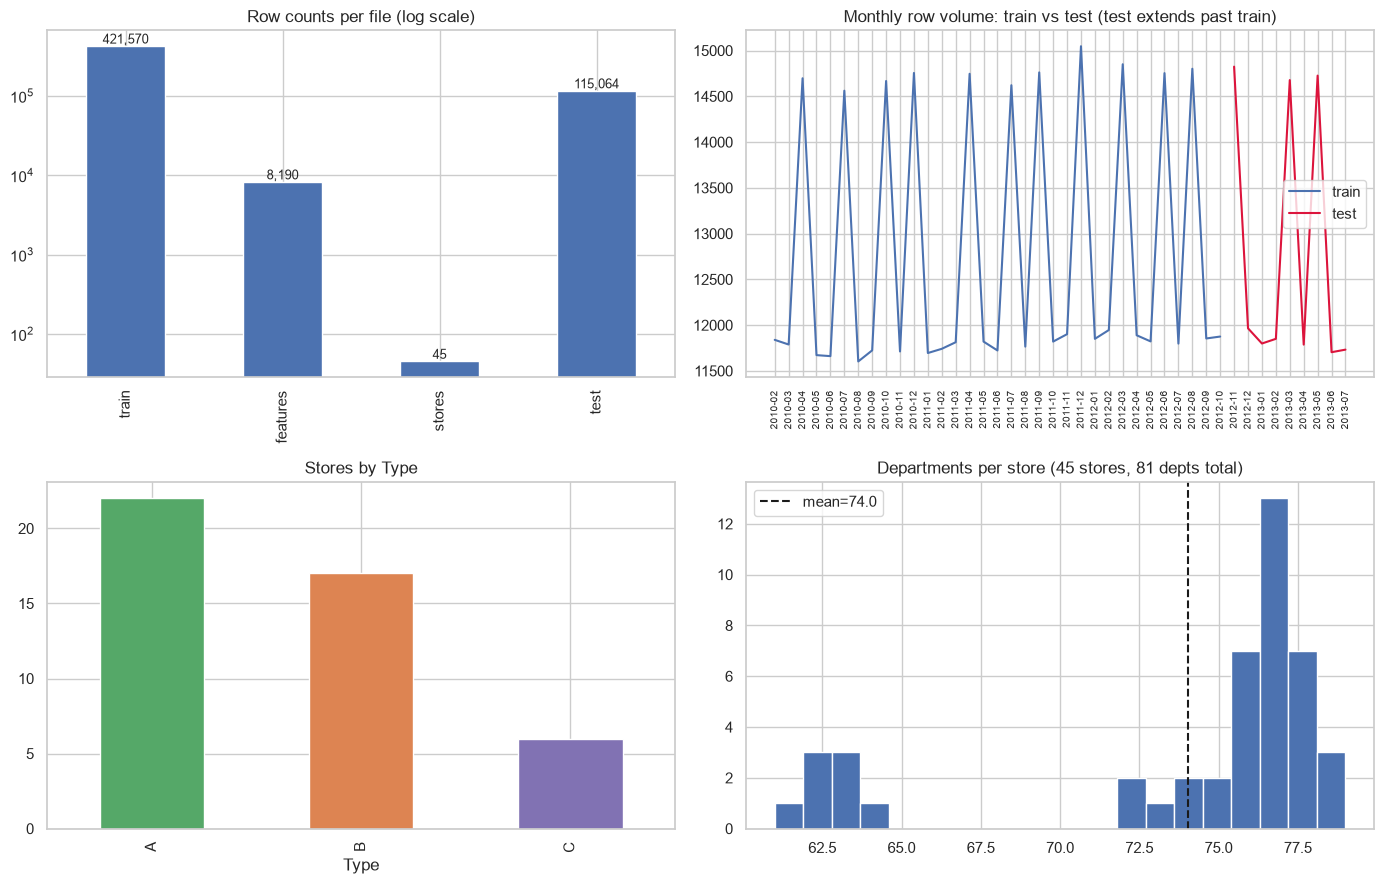

saved figures/phase1/25_dataset_cartography.png


In [2]:
# 25 — Dataset cartography: files, timeline, stores, dept coverage
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
shapes = pd.Series({'train': len(tr), 'features': len(fe), 'stores': len(st), 'test': len(te)})
shapes.plot.bar(ax=ax[0, 0], color='#4C72B0')
ax[0, 0].set_title('Row counts per file (log scale)')
ax[0, 0].set_yscale('log')
for i, v in enumerate(shapes.values): ax[0, 0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

mtr = tr.groupby(tr['Date'].dt.to_period('M')).size()
mte = te.groupby(te['Date'].dt.to_period('M')).size()
ax[0, 1].plot(mtr.index.astype(str), mtr.values, label='train', color='#4C72B0')
ax[0, 1].plot(mte.index.astype(str), mte.values, label='test', color='crimson')
ax[0, 1].set_title('Monthly row volume: train vs test (test extends past train)')
ax[0, 1].tick_params(axis='x', rotation=90, labelsize=7)
ax[0, 1].legend()

st['Type'].value_counts().reindex(['A', 'B', 'C']).plot.bar(ax=ax[1, 0], color=['#55A868', '#DD8452', '#8172B3'])
ax[1, 0].set_title('Stores by Type')
dps = tr.groupby('Store')['Dept'].nunique()
ax[1, 1].hist(dps.values, bins=20, color='#4C72B0')
ax[1, 1].axvline(dps.mean(), color='k', ls='--', label=f'mean={dps.mean():.1f}')
ax[1, 1].set_title('Departments per store (45 stores, 81 depts total)')
ax[1, 1].legend()
savefig('25_dataset_cartography')


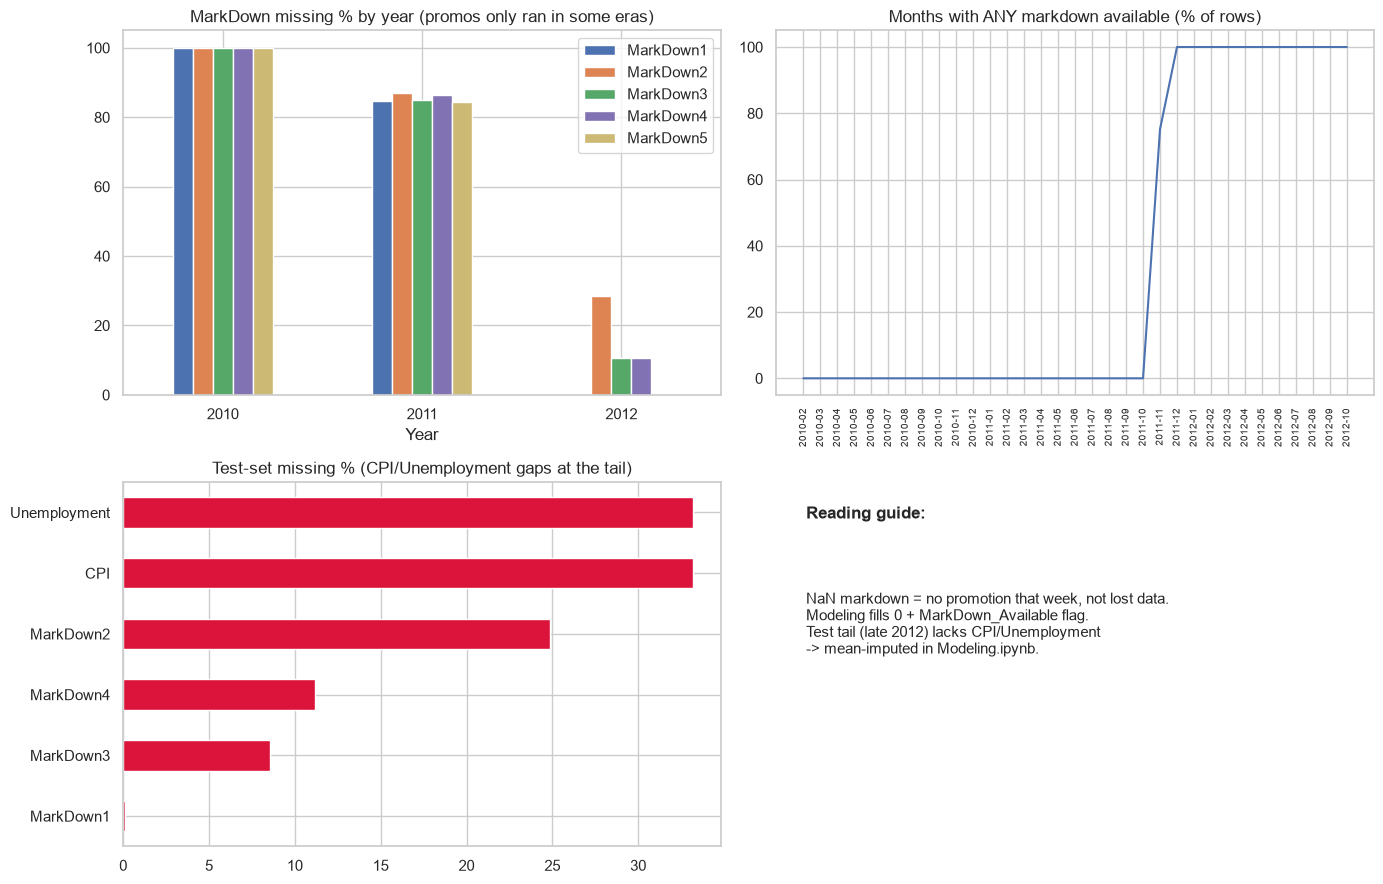

saved figures/phase1/26_missingness_deepdive.png


In [3]:
# 26 — Missingness deep-dive: markdowns by year, availability over time, test exogenous gaps
miss_yr = df.groupby('Year')[MD].apply(lambda g: g.isna().mean() * 100)
avail_m = (df[MD].notna().any(axis=1)).groupby(df['Date'].dt.to_period('M')).mean() * 100
dft = te.merge(fe.drop(columns=['IsHoliday']), on=['Store', 'Date'], how='left')
test_miss = dft.isna().mean() * 100

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
miss_yr.plot.bar(ax=ax[0, 0], color=['#4C72B0', '#DD8452', '#55A868', '#8172B3', '#CCB974'])
ax[0, 0].set_title('MarkDown missing % by year (promos only ran in some eras)')
ax[0, 0].tick_params(axis='x', rotation=0)
ax[0, 1].plot(avail_m.index.astype(str), avail_m.values, color='#4C72B0')
ax[0, 1].set_title('Months with ANY markdown available (% of rows)')
ax[0, 1].tick_params(axis='x', rotation=90, labelsize=7)
test_miss[test_miss > 0].sort_values().plot.barh(ax=ax[1, 0], color='crimson')
ax[1, 0].set_title('Test-set missing % (CPI/Unemployment gaps at the tail)')
ax[1, 1].axis('off')
ax[1, 1].text(0.05, 0.9, 'Reading guide:', weight='bold', fontsize=12, transform=ax[1, 1].transAxes)
ax[1, 1].text(0.05, 0.7, 'NaN markdown = no promotion that week, not lost data.\nModeling fills 0 + MarkDown_Available flag.\nTest tail (late 2012) lacks CPI/Unemployment\n-> mean-imputed in Modeling.ipynb.', fontsize=11, va='top', transform=ax[1, 1].transAxes)
savefig('26_missingness_deepdive')


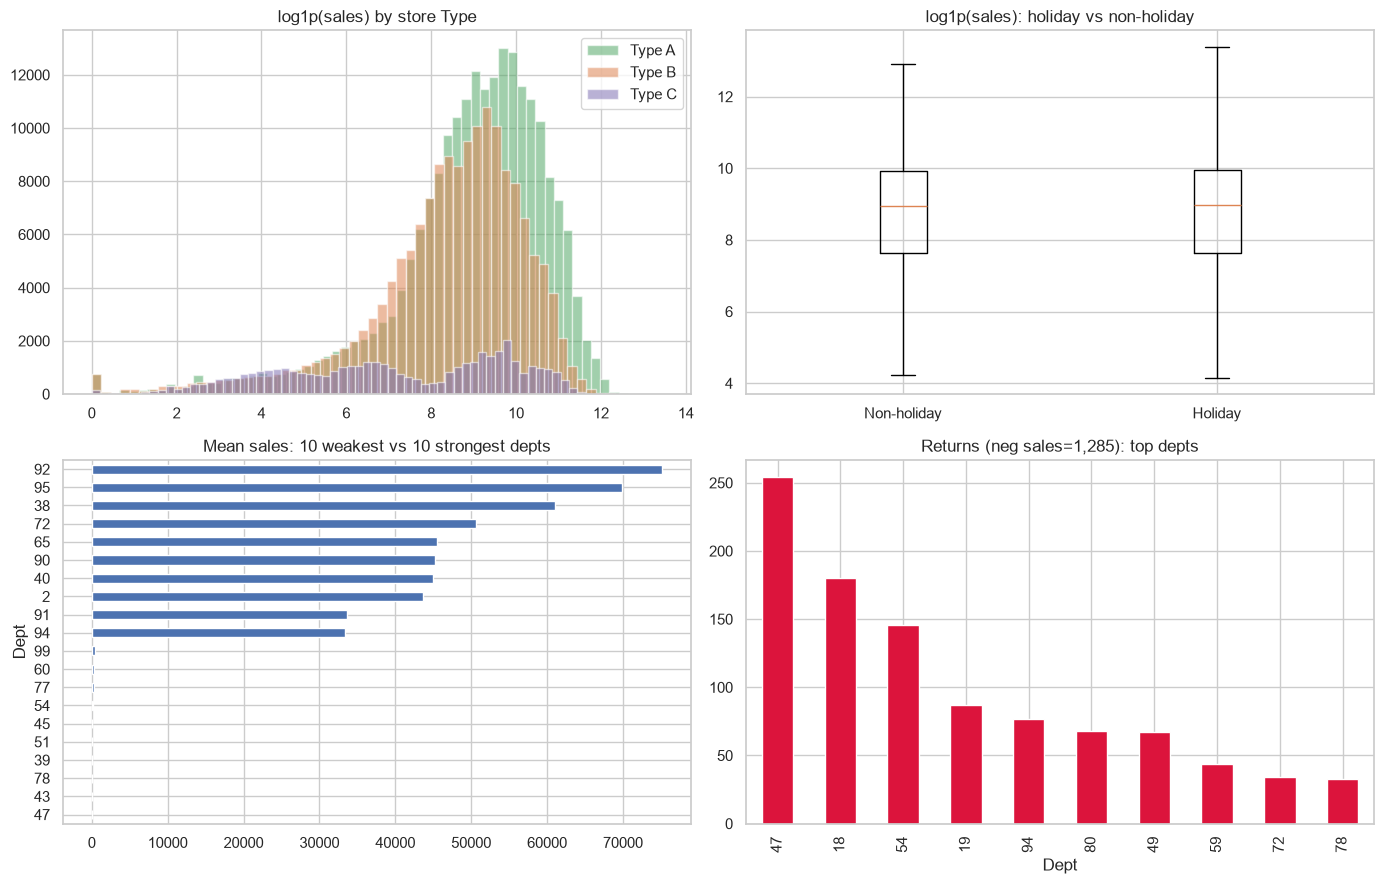

saved figures/phase1/27_sales_anatomy.png


In [4]:
# 27 — Sales anatomy: shape by Type/holiday, dept extremes, returns
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for t, c in zip(['A', 'B', 'C'], ['#55A868', '#DD8452', '#8172B3']):
    s = np.log1p(df.loc[df['Type'] == t, 'Weekly_Sales'].clip(lower=0))
    ax[0, 0].hist(s, bins=60, alpha=0.55, label=f'Type {t}', color=c)
ax[0, 0].set_title('log1p(sales) by store Type')
ax[0, 0].legend()
hol = df['IsHoliday'].astype(int)
parts = [np.log1p(df.loc[hol == k, 'Weekly_Sales'].clip(lower=0)) for k in (0, 1)]
ax[0, 1].boxplot(parts, tick_labels=['Non-holiday', 'Holiday'], showfliers=False)
ax[0, 1].set_title('log1p(sales): holiday vs non-holiday')
dm = df.groupby('Dept')['Weekly_Sales'].mean().sort_values()
pd.concat([dm.head(10), dm.tail(10)]).plot.barh(ax=ax[1, 0], color='#4C72B0')
ax[1, 0].set_title('Mean sales: 10 weakest vs 10 strongest depts')
neg = df.loc[df['Weekly_Sales'] < 0].groupby('Dept').size().sort_values(ascending=False).head(10)
neg.plot.bar(ax=ax[1, 1], color='crimson')
ax[1, 1].set_title(f"Returns (neg sales={len(df[df['Weekly_Sales']<0]):,}): top depts")
savefig('27_sales_anatomy')


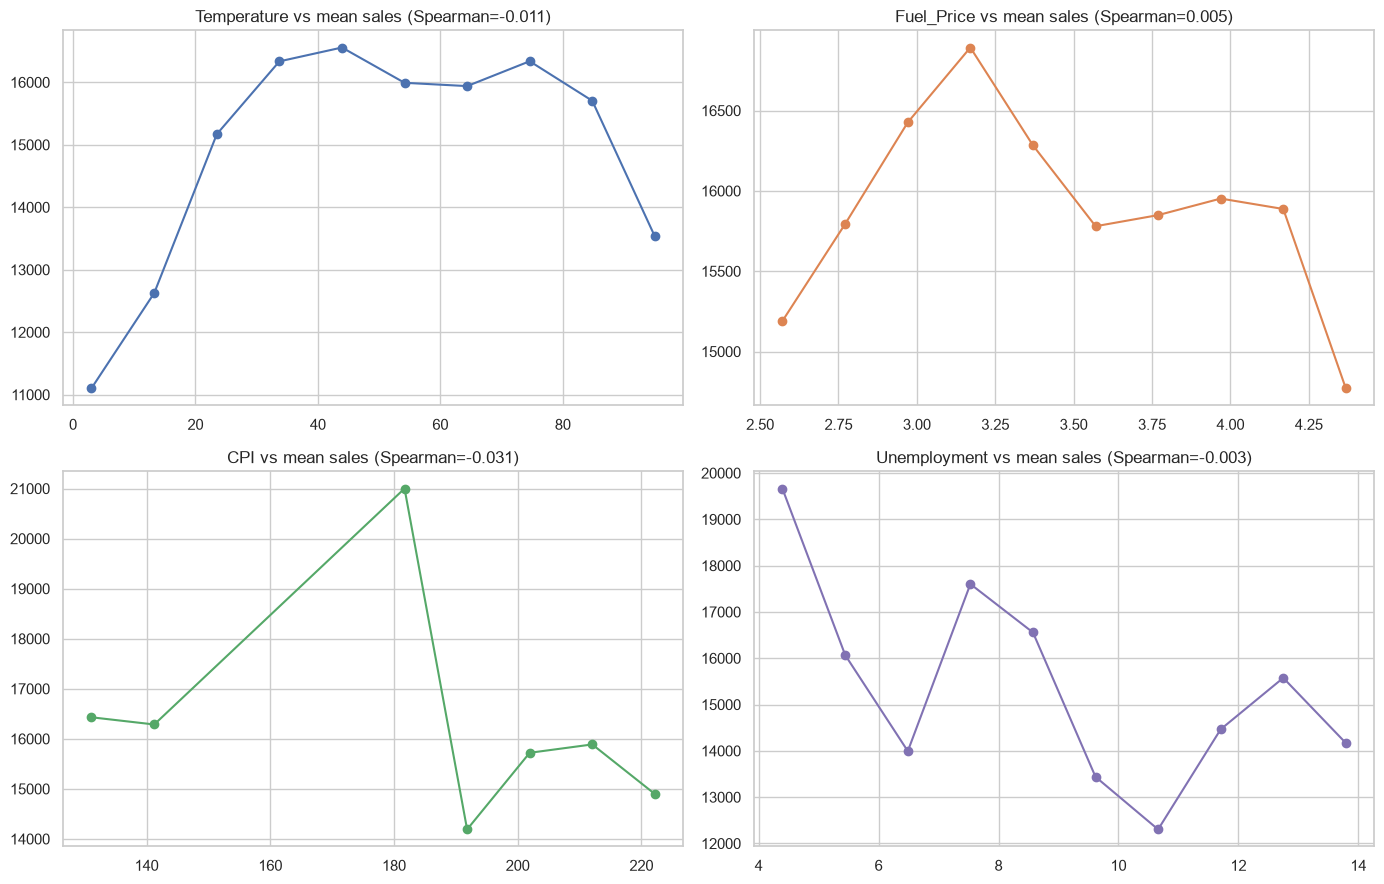

saved figures/phase1/28_exogenous_relationships.png


In [5]:
# 28 — Exogenous relationships: binned mean sales vs Temperature/Fuel/CPI/Unemployment
corr = R['corr_with_target']
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, col, c in zip(ax.flat, ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment'], ['#4C72B0', '#DD8452', '#55A868', '#8172B3']):
    b = pd.cut(df[col], 10)
    m = df.groupby(b, observed=True)['Weekly_Sales'].mean()
    a.plot([i.mid for i in m.index], m.values, 'o-', color=c)
    a.set_title(f"{col} vs mean sales (Spearman={corr.get(col, float('nan')):.3f})")
savefig('28_exogenous_relationships')


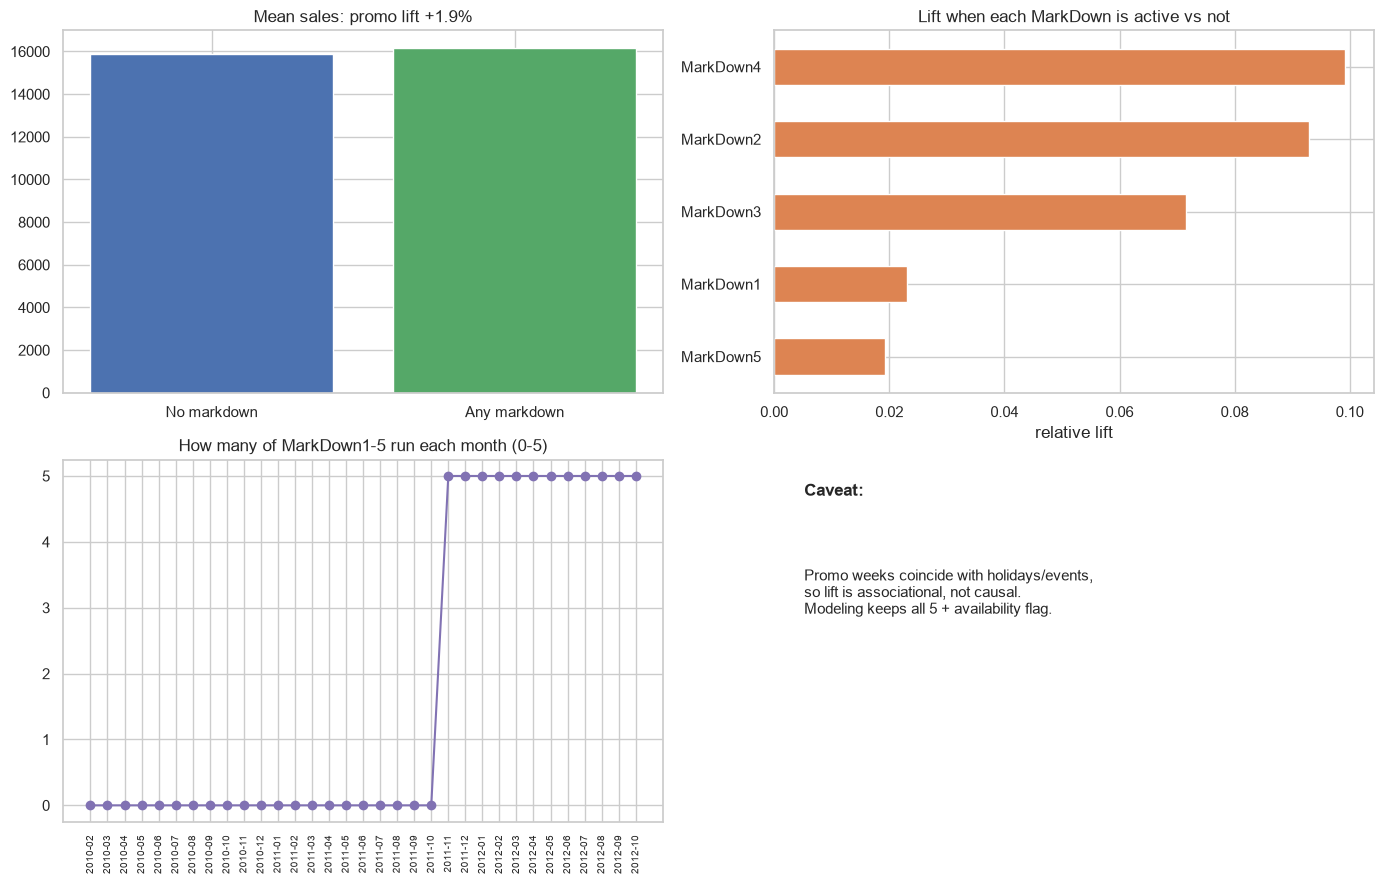

saved figures/phase1/29_promotions.png


In [6]:
# 29 — Promotions: does an active markdown lift sales?
avail = df[MD].notna().any(axis=1)
lift = df.groupby(avail)['Weekly_Sales'].mean()
per_md = pd.Series({m: df.loc[df[m] > 0, 'Weekly_Sales'].mean() / df.loc[~(df[m] > 0), 'Weekly_Sales'].mean() - 1 for m in MD})
cnt_m = df.groupby(df['Date'].dt.to_period('M'))[MD].apply(lambda g: g.notna().any().sum())

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0, 0].bar(['No markdown', 'Any markdown'], lift.values, color=['#4C72B0', '#55A868'])
ax[0, 0].set_title(f"Mean sales: promo lift {lift.loc[True]/lift.loc[False]-1:+.1%}")
per_md.sort_values().plot.barh(ax=ax[0, 1], color='#DD8452')
ax[0, 1].set_title('Lift when each MarkDown is active vs not')
ax[0, 1].set_xlabel('relative lift')
ax[1, 0].plot(cnt_m.index.astype(str), cnt_m.values, 'o-', color='#8172B3')
ax[1, 0].set_title('How many of MarkDown1-5 run each month (0-5)')
ax[1, 0].tick_params(axis='x', rotation=90, labelsize=7)
ax[1, 1].axis('off')
ax[1, 1].text(0.05, 0.9, 'Caveat:', weight='bold', fontsize=12, transform=ax[1, 1].transAxes)
ax[1, 1].text(0.05, 0.7, 'Promo weeks coincide with holidays/events,\nso lift is associational, not causal.\nModeling keeps all 5 + availability flag.', fontsize=11, va='top', transform=ax[1, 1].transAxes)
savefig('29_promotions')


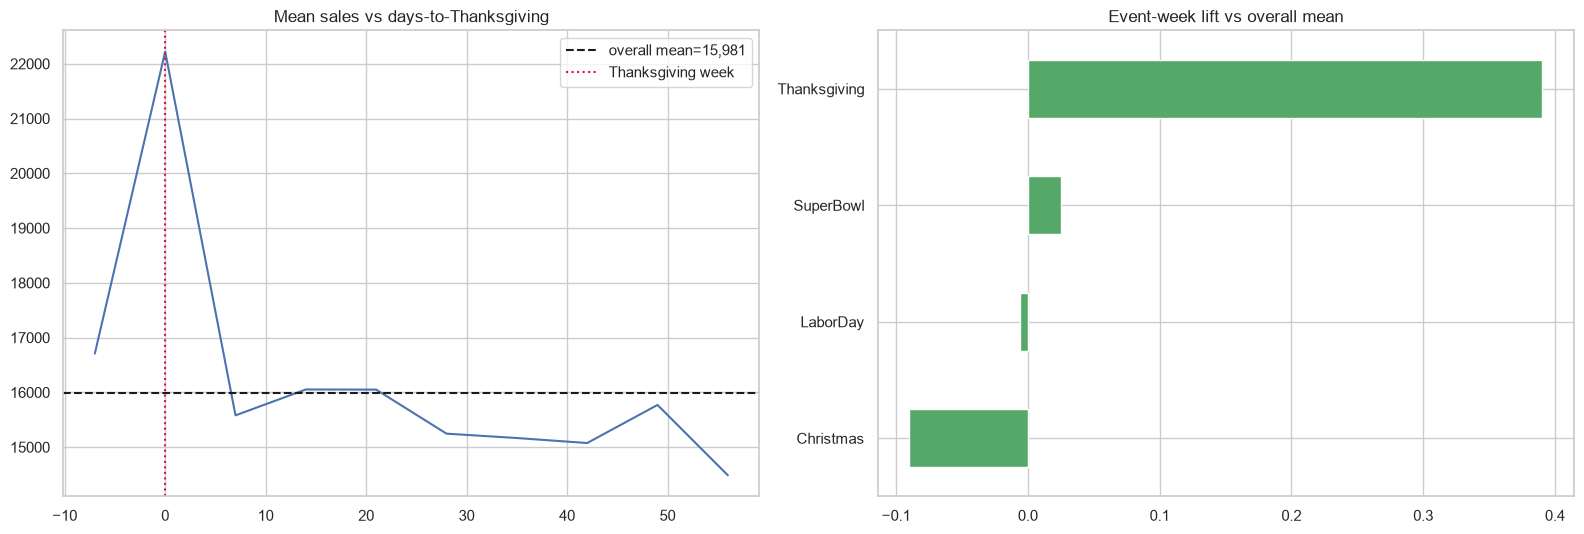

saved figures/phase1/30_calendar_windows.png
['01_eda_overview.png', '02_correlation.png', '03_before_reduction.png', '04_pca_scree_loadings.png', '05_linear_embeddings.png', '06_all_embeddings.png', '07_clustering_before_after.png', '08_filter_scores.png', '09_embedded.png', '10_metaheuristic_convergence.png', '11_selection_frequency.png', '12_cv_boxplot.png', '13_confusion_matrices.png', '14_roc_curves.png', '15_over_under_fitting.png', '16_subset_comparison.png', '17_reduction_after_selection.png', '18_preprocessing_effect.png', '19_temporal_structure.png', '20_dept_store_dominance.png', '21_embedding_quality_summary.png', '22_cluster_composition.png', '22_cluster_quality_elbow.png', '23_f1_vs_dims.png', '23_selection_overlap.png', '24_error_analysis.png', '25_dataset_cartography.png', '26_missingness_deepdive.png', '27_sales_anatomy.png', '28_exogenous_relationships.png', '29_promotions.png', '30_calendar_windows.png']


In [7]:
# 30 — Calendar windows: Thanksgiving/Christmas distance + event-week spikes
thanks = {2010: '2010-11-26', 2011: '2011-11-25', 2012: '2012-11-23'}
xmas = {2010: '2010-12-31', 2011: '2011-12-30', 2012: '2012-12-28'}
df['Days_to_Thanksgiving'] = (pd.to_datetime(df['Year'].map(thanks)) - df['Date']).dt.days
ev = {'SuperBowl': ['2010-02-12', '2011-02-11', '2012-02-10'], 'LaborDay': ['2010-09-10', '2011-09-09', '2012-09-07'],
      'Thanksgiving': ['2010-11-26', '2011-11-25', '2012-11-23'], 'Christmas': ['2010-12-31', '2011-12-30', '2012-12-28']}
win = df[(df['Days_to_Thanksgiving'] >= -7) & (df['Days_to_Thanksgiving'] <= 60)]
curve = win.groupby('Days_to_Thanksgiving')['Weekly_Sales'].mean()
base = df['Weekly_Sales'].mean()
spike = pd.Series({k: df.loc[df['Date'].isin(pd.to_datetime(v)), 'Weekly_Sales'].mean() / base - 1 for k, v in ev.items()})

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].plot(curve.index, curve.values, color='#4C72B0')
ax[0].axhline(base, ls='--', c='k', label=f'overall mean={base:,.0f}')
ax[0].axvline(0, ls=':', c='crimson', label='Thanksgiving week')
ax[0].set_title('Mean sales vs days-to-Thanksgiving')
ax[0].legend()
spike.sort_values().plot.barh(ax=ax[1], color='#55A868')
ax[1].set_title('Event-week lift vs overall mean')
savefig('30_calendar_windows')
print(sorted(os.listdir(FIG)))


---
# Part 2 — Model visualizations


# Extra Visuals — Phase 1 (standalone)

Companion to `Modeling.ipynb` (left untouched). Reads only exported aggregates in `results/phase1_results/` plus raw CSVs for plots 18–20, and writes:

`figures/phase1/18_preprocessing_effect.png` … `24_error_analysis.png`

Run top-to-bottom. No retraining, no `Modeling.ipynb` rerun.

In [8]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid')
RS = 42
RES = 'results/phase1_results'
FIG = 'figures/phase1'
os.makedirs(FIG, exist_ok=True)

# raw data lives next door (read-only); fall back to ./Datasets if mirrored locally
DATA = '../last/Datasets' if os.path.isdir('../last/Datasets') else 'Datasets'
print('DATA =', DATA, '| exists:', os.path.isdir(DATA))

R = json.load(open(f'{RES}/phase1_results.json'))
hold = pd.read_csv(f'{RES}/01_holdout_metrics.csv', index_col='Model')
embq = pd.read_csv(f'{RES}/03_embedding_quality.csv', index_col='Method')
clu = pd.read_csv(f'{RES}/04_clustering_before_after.csv', index_col='Space')
subs = pd.read_csv(f'{RES}/07_selected_feature_subsets.csv', index_col='Method')
subeval = pd.read_csv(f'{RES}/09_best_model_on_each_subset.csv', index_col='Input')
cmi = pd.read_csv(f'{RES}/11_confusion_interpretation.csv', index_col='Model')
FEATURES = R['features']
t1, t2 = R['target']['t1'], R['target']['t2']

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    print('saved', f'{FIG}/{name}.png')


DATA = ../last/Datasets | exists: True


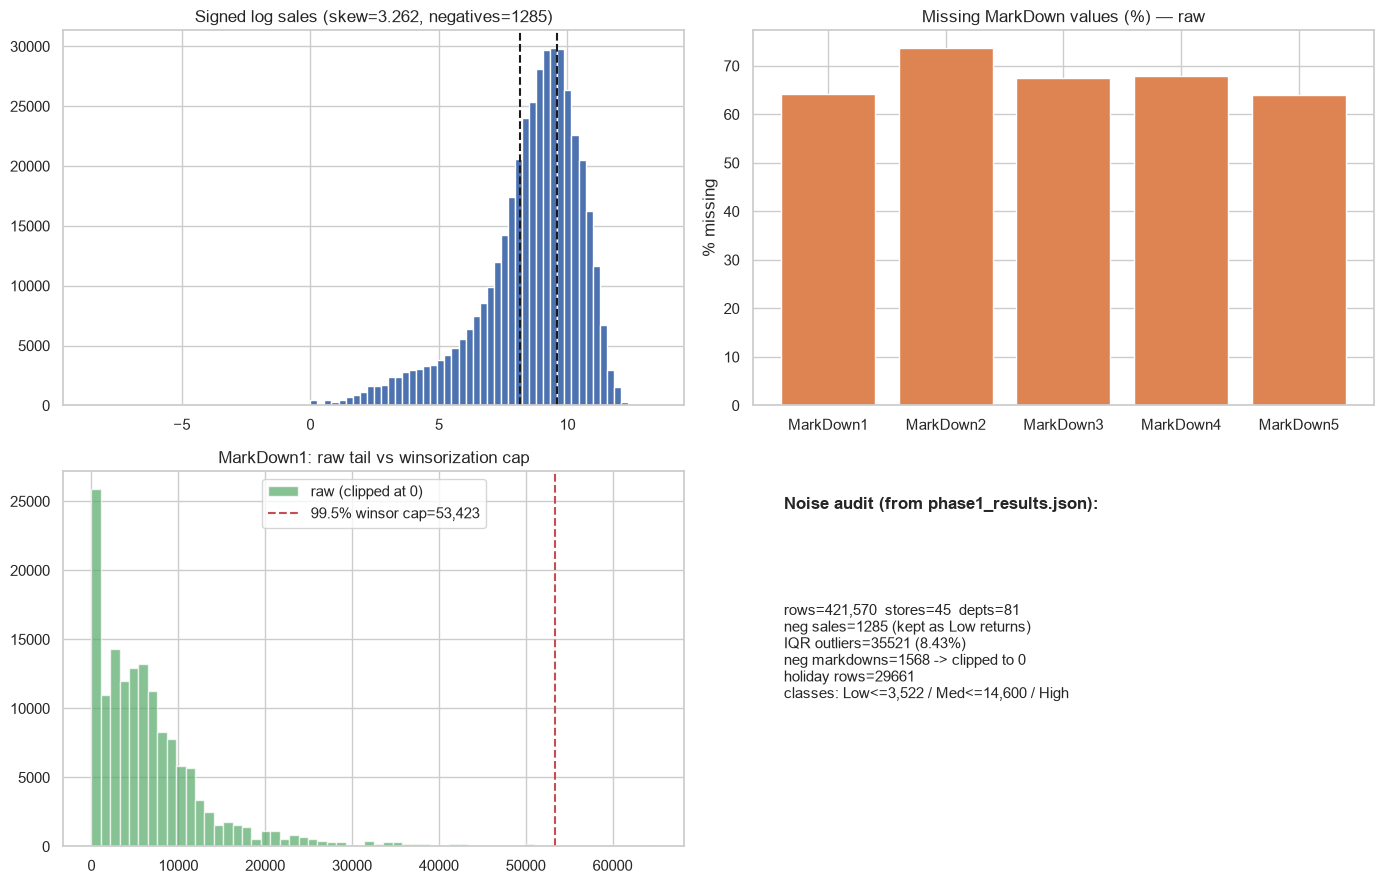

saved figures/phase1/18_preprocessing_effect.png


In [9]:
# 18 — Preprocessing effect: signed-log sales, missingness, winsorization, negatives
tr = pd.read_csv(f'{DATA}/train.csv', parse_dates=['Date'])
fe = pd.read_csv(f'{DATA}/features.csv', parse_dates=['Date'])
st = pd.read_csv(f'{DATA}/stores.csv')
df = tr.merge(fe.drop(columns=['IsHoliday']), on=['Store', 'Date'], how='left').merge(st, on='Store', how='left')
md = [f'MarkDown{i}' for i in range(1, 6)]

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
signed = np.sign(df['Weekly_Sales']) * np.log1p(df['Weekly_Sales'].abs())
ax[0, 0].hist(signed, bins=80, color='#4C72B0')
for t in (t1, t2): ax[0, 0].axvline(np.log1p(t), color='k', ls='--')
ax[0, 0].set_title(f"Signed log sales (skew={R['data']['sales_skew']}, negatives={R['data']['neg_sales']})")

miss = df[md].isna().mean() * 100
ax[0, 1].bar(miss.index, miss.values, color='#DD8452')
ax[0, 1].set_title('Missing MarkDown values (%) — raw')
ax[0, 1].set_ylabel('% missing')

raw1 = df['MarkDown1'].dropna().clip(lower=0)
cap = raw1.quantile(0.995)
ax[1, 0].hist(raw1[raw1 < raw1.quantile(0.999)], bins=60, color='#55A868', alpha=0.7, label='raw (clipped at 0)')
ax[1, 0].axvline(cap, color='r', ls='--', label=f'99.5% winsor cap={cap:,.0f}')
ax[1, 0].set_title('MarkDown1: raw tail vs winsorization cap')
ax[1, 0].legend()

ax[1, 1].axis('off')
ax[1, 1].text(0.05, 0.9, 'Noise audit (from phase1_results.json):', fontsize=12, weight='bold', transform=ax[1, 1].transAxes)
txt = (f"rows={R['data']['n_rows']:,}  stores={R['data']['n_stores']}  depts={R['data']['n_depts']}\n"
       f"neg sales={R['data']['neg_sales']} (kept as Low returns)\n"
       f"IQR outliers={R['data']['iqr_outliers']} ({R['data']['iqr_outliers']/R['data']['n_rows']*100:.2f}%)\n"
       f"neg markdowns={R['data']['neg_markdowns']} -> clipped to 0\n"
       f"holiday rows={R['data']['holiday_rows']}\n"
       f"classes: Low<={t1:,.0f} / Med<={t2:,.0f} / High")
ax[1, 1].text(0.05, 0.65, txt, fontsize=11, va='top', transform=ax[1, 1].transAxes)
savefig('18_preprocessing_effect')


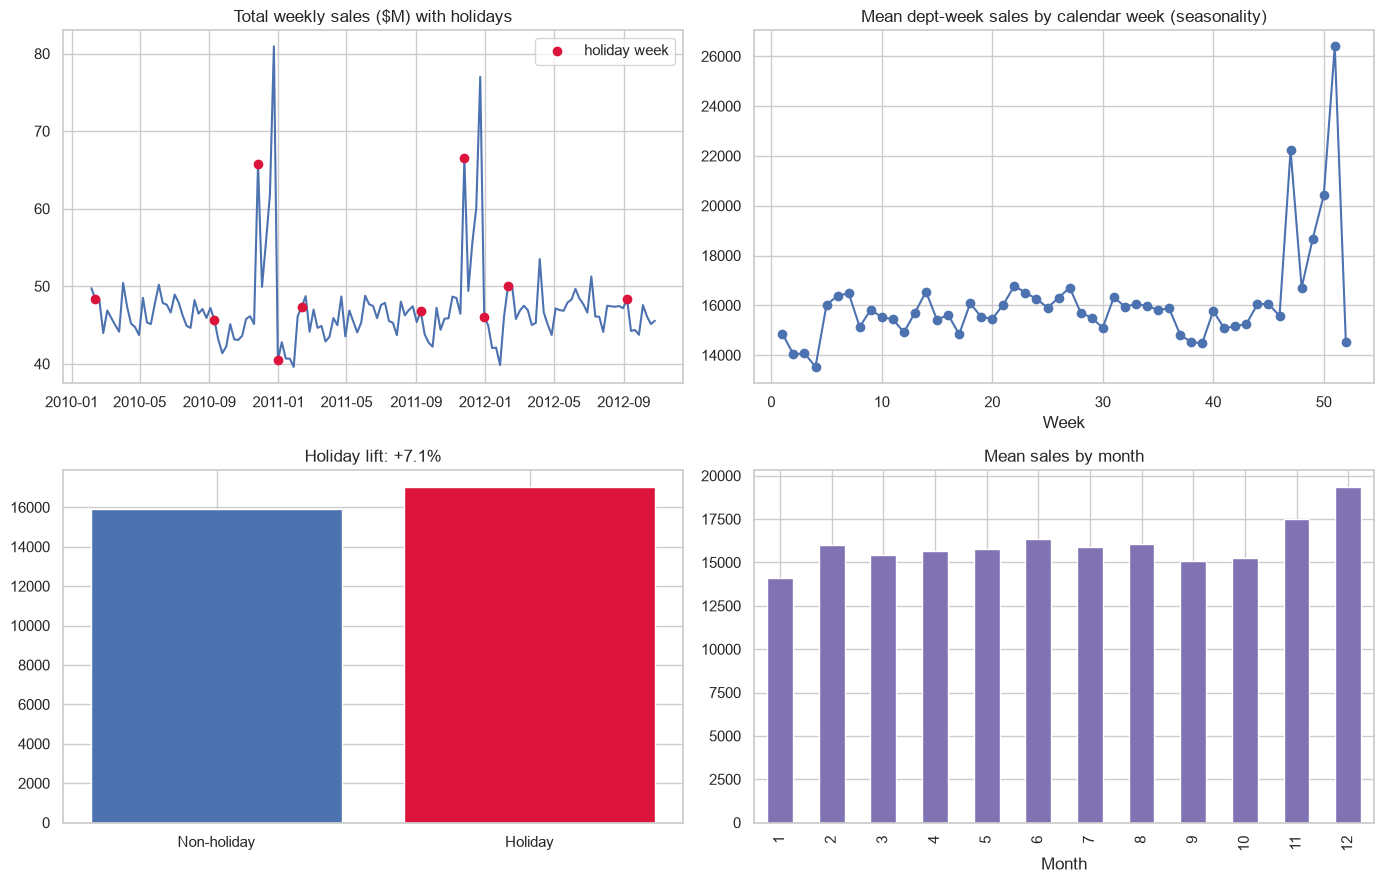

saved figures/phase1/19_temporal_structure.png


In [10]:
# 19 — Temporal structure: weekly totals + holidays, seasonality, holiday lift
wk = df.groupby('Date')['Weekly_Sales'].sum() / 1e6
hol = df.loc[df['IsHoliday'] == 1, 'Date'].unique()
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['Month'] = df['Date'].dt.month
by_week = df.groupby('Week')['Weekly_Sales'].mean()
lift = df.groupby('IsHoliday')['Weekly_Sales'].mean()

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0, 0].plot(wk.index, wk.values, color='#4C72B0')
ax[0, 0].scatter(hol, wk.loc[hol], color='crimson', zorder=3, label='holiday week')
ax[0, 0].set_title('Total weekly sales ($M) with holidays')
ax[0, 0].legend()
ax[0, 1].plot(by_week.index, by_week.values, 'o-', color='#4C72B0')
ax[0, 1].set_title('Mean dept-week sales by calendar week (seasonality)')
ax[0, 1].set_xlabel('Week')
ax[1, 0].bar(['Non-holiday', 'Holiday'], lift.values, color=['#4C72B0', 'crimson'])
ax[1, 0].set_title(f"Holiday lift: {lift.iloc[1]/lift.iloc[0]-1:+.1%}")
df.groupby('Month')['Weekly_Sales'].mean().plot.bar(ax=ax[1, 1], color='#8172B3')
ax[1, 1].set_title('Mean sales by month')
savefig('19_temporal_structure')


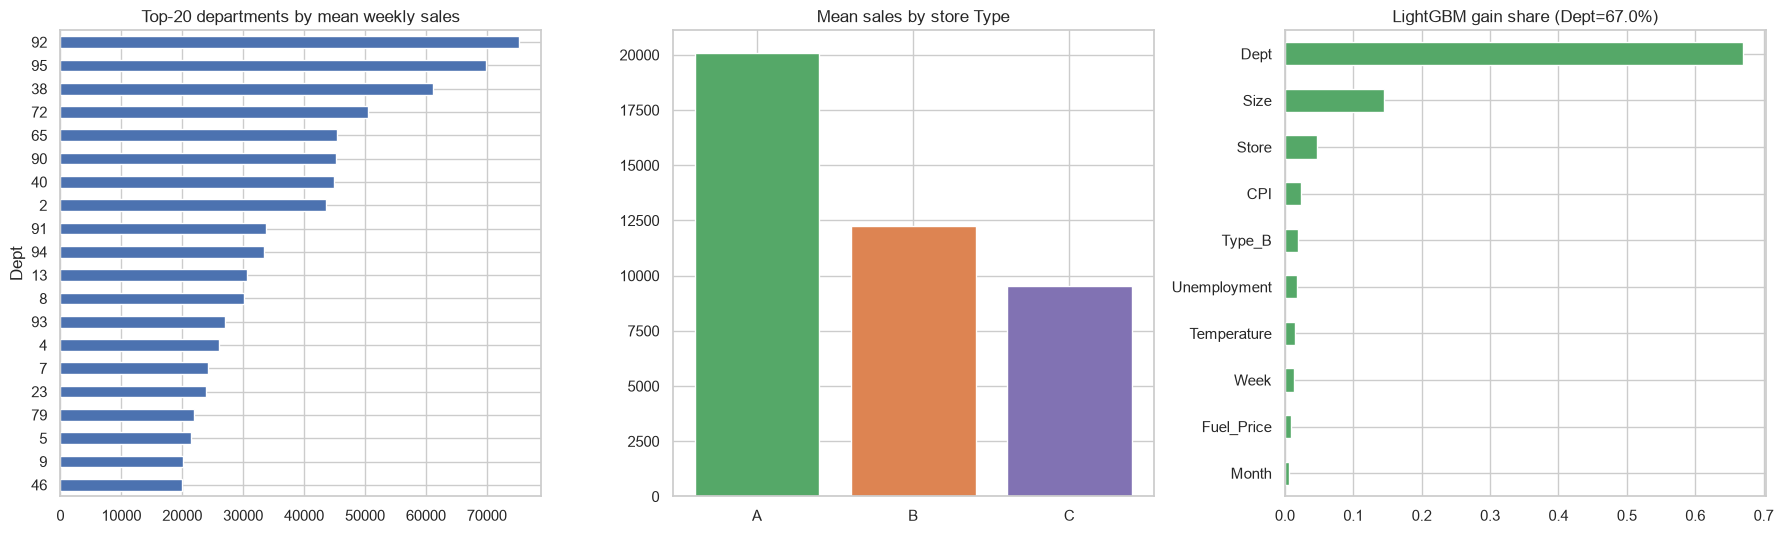

saved figures/phase1/20_dept_store_dominance.png


In [11]:
# 20 — Dept/Store dominance + LightGBM gain share
top_dept = df.groupby('Dept')['Weekly_Sales'].mean().sort_values(ascending=False).head(20)
by_type = df.groupby('Type')['Weekly_Sales'].mean()
gain = pd.Series(R['lgb_gain_share']).sort_values()

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
top_dept.sort_values().plot.barh(ax=ax[0], color='#4C72B0')
ax[0].set_title('Top-20 departments by mean weekly sales')
ax[1].bar(by_type.index, by_type.values, color=['#55A868', '#DD8452', '#8172B3'])
ax[1].set_title('Mean sales by store Type')
gain.tail(10).plot.barh(ax=ax[2], color='#55A868')
ax[2].set_title(f"LightGBM gain share (Dept={R['lgb_gain_share']['Dept']:.1%})")
savefig('20_dept_store_dominance')


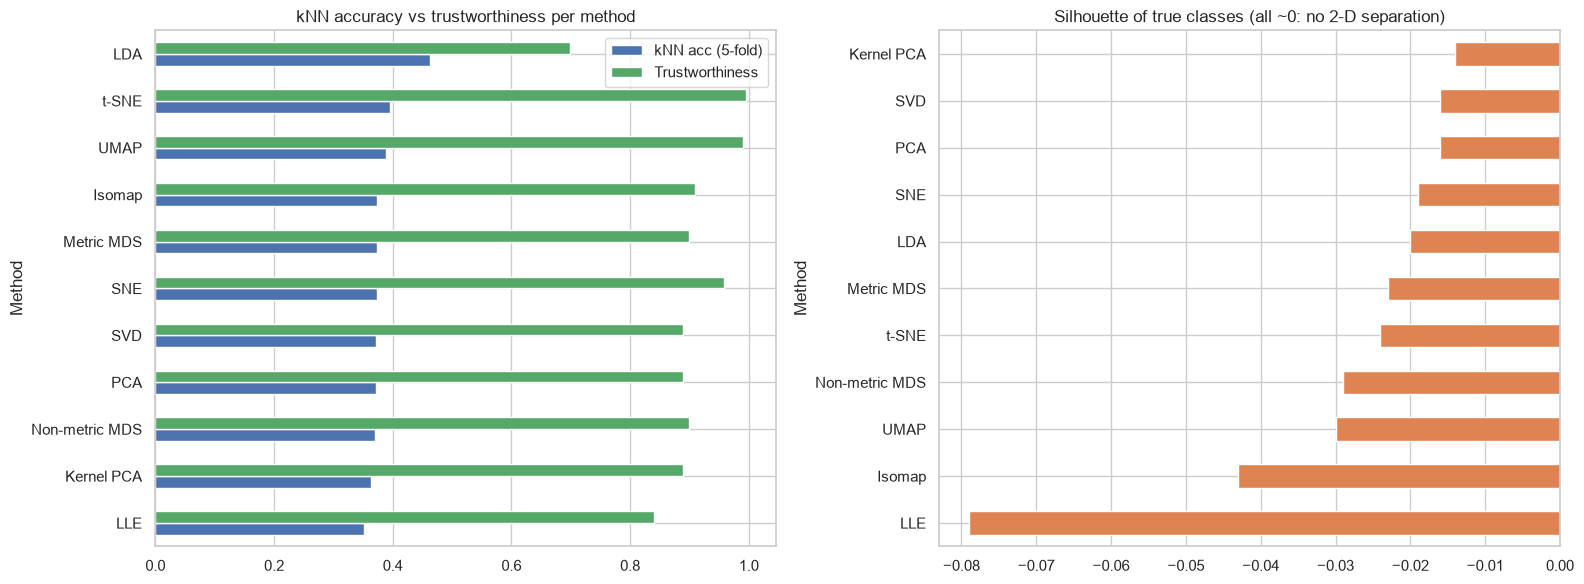

saved figures/phase1/21_embedding_quality_summary.png


In [12]:
# 21 — Embedding quality summary (from 03_embedding_quality.csv)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
embq[['kNN acc (5-fold)', 'Trustworthiness']].sort_values('kNN acc (5-fold)').plot.barh(ax=ax[0], color=['#4C72B0', '#55A868'])
ax[0].set_title('kNN accuracy vs trustworthiness per method')
embq['Silhouette (true classes)'].sort_values().plot.barh(ax=ax[1], color='#DD8452')
ax[1].set_title('Silhouette of true classes (all ~0: no 2-D separation)')
savefig('21_embedding_quality_summary')


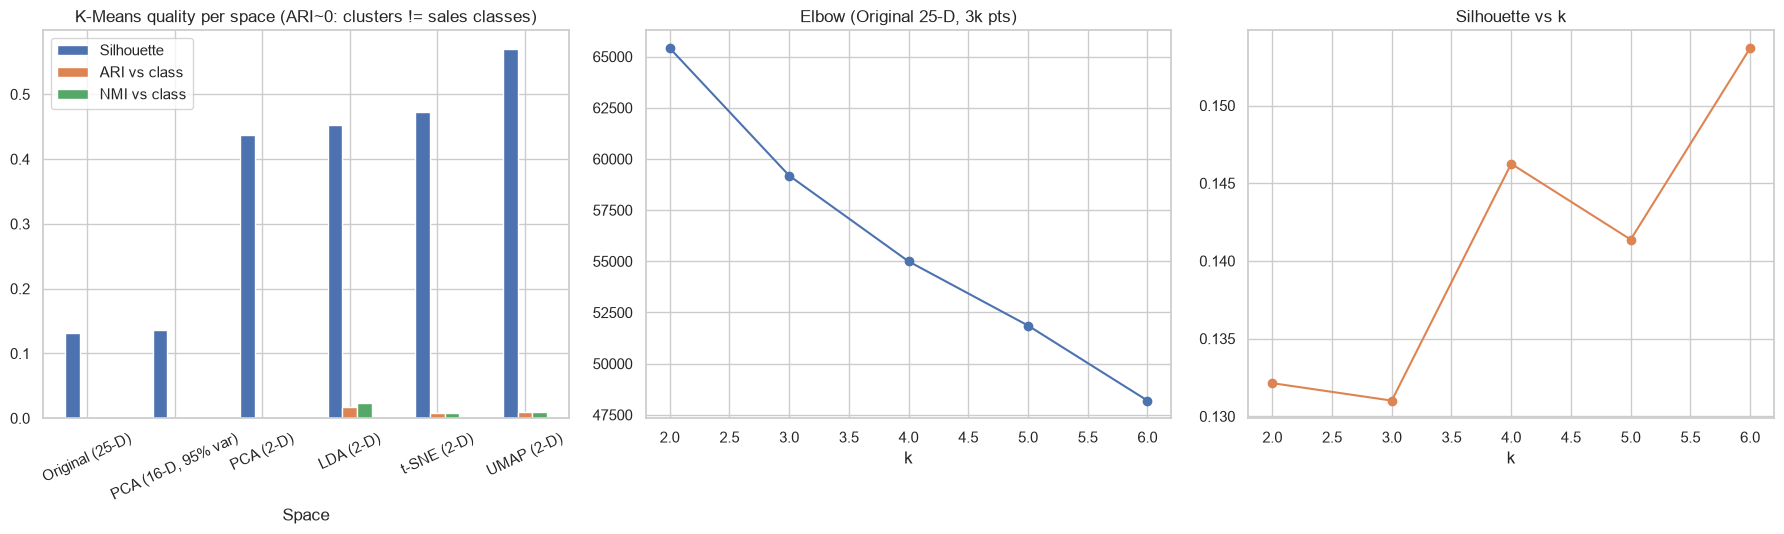

saved figures/phase1/22_cluster_quality_elbow.png


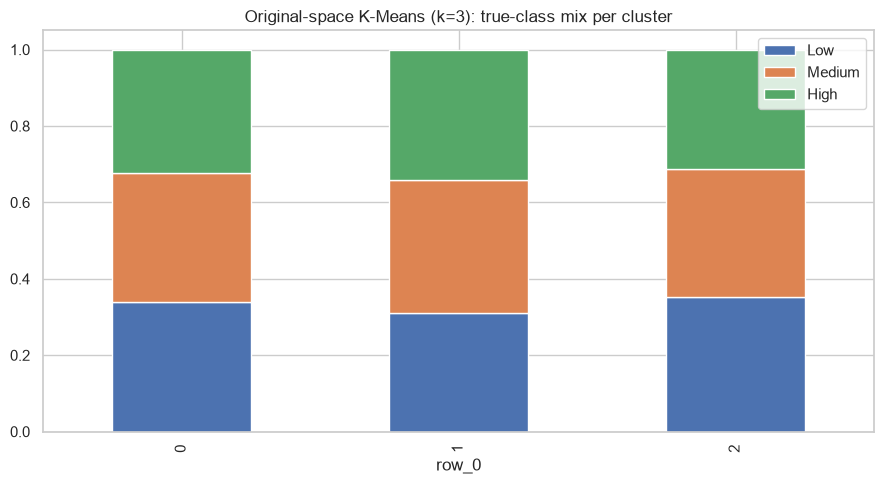

saved figures/phase1/22_cluster_composition.png


In [13]:
# 22 — Clustering: quality bars + elbow k=2..6 + Original-space composition
# rebuild 25 features exactly as Modeling.ipynb, 3000-pt sample RS=42
thanks = {2010: '2010-11-26', 2011: '2011-11-25', 2012: '2012-11-23'}
xmas = {2010: '2010-12-31', 2011: '2011-12-30', 2012: '2012-12-28'}
df['Year'] = df['Date'].dt.year
df['Day'] = df['Date'].dt.day
df['Days_to_Thanksgiving'] = (pd.to_datetime(df['Year'].map(thanks)) - df['Date']).dt.days
df['Days_to_Christmas'] = (pd.to_datetime(df['Year'].map(xmas)) - df['Date']).dt.days
df['SuperBowl'] = df['Date'].isin(pd.to_datetime(['2010-02-12', '2011-02-11', '2012-02-10'])).astype(int)
df['LaborDay'] = df['Date'].isin(pd.to_datetime(['2010-09-10', '2011-09-09', '2012-09-07'])).astype(int)
df['MarkDown_Available'] = df[md].notna().any(axis=1).astype(int)
df[md] = df[md].fillna(0).clip(lower=0)
for c in md: df[c] = df[c].clip(upper=df[c].quantile(0.995))
df['IsHoliday'] = df['IsHoliday'].astype(int)
df = pd.concat([df, pd.get_dummies(df['Type'], prefix='Type').astype(int)], axis=1)
df['Sales_Class'] = np.select([df['Weekly_Sales'] <= t1, df['Weekly_Sales'] <= t2], [0, 1], 2)
X = df[FEATURES].astype(float)
idx = np.random.RandomState(RS).choice(len(X), 3000, replace=False)
Xs = StandardScaler().fit_transform(X.iloc[idx])
yv = df['Sales_Class'].values[idx]

ks, inert, sil = list(range(2, 7)), [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(Xs)
    inert.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
km3 = KMeans(3, n_init=10, random_state=RS).fit(Xs)
ct = pd.crosstab(km3.labels_, yv, normalize='index')

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
clu[['Silhouette', 'ARI vs class', 'NMI vs class']].plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452', '#55A868'])
ax[0].set_title('K-Means quality per space (ARI~0: clusters != sales classes)')
ax[0].tick_params(axis='x', rotation=25)
a1 = ax[1]; a1.plot(ks, inert, 'o-', color='#4C72B0'); a1.set_title('Elbow (Original 25-D, 3k pts)'); a1.set_xlabel('k')
a2 = ax[2]; a2.plot(ks, sil, 'o-', color='#DD8452'); a2.set_title('Silhouette vs k'); a2.set_xlabel('k')
savefig('22_cluster_quality_elbow')

ct.columns = ['Low', 'Medium', 'High']
ct.plot.bar(stacked=True, figsize=(9, 5), color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Original-space K-Means (k=3): true-class mix per cluster')
savefig('22_cluster_composition')


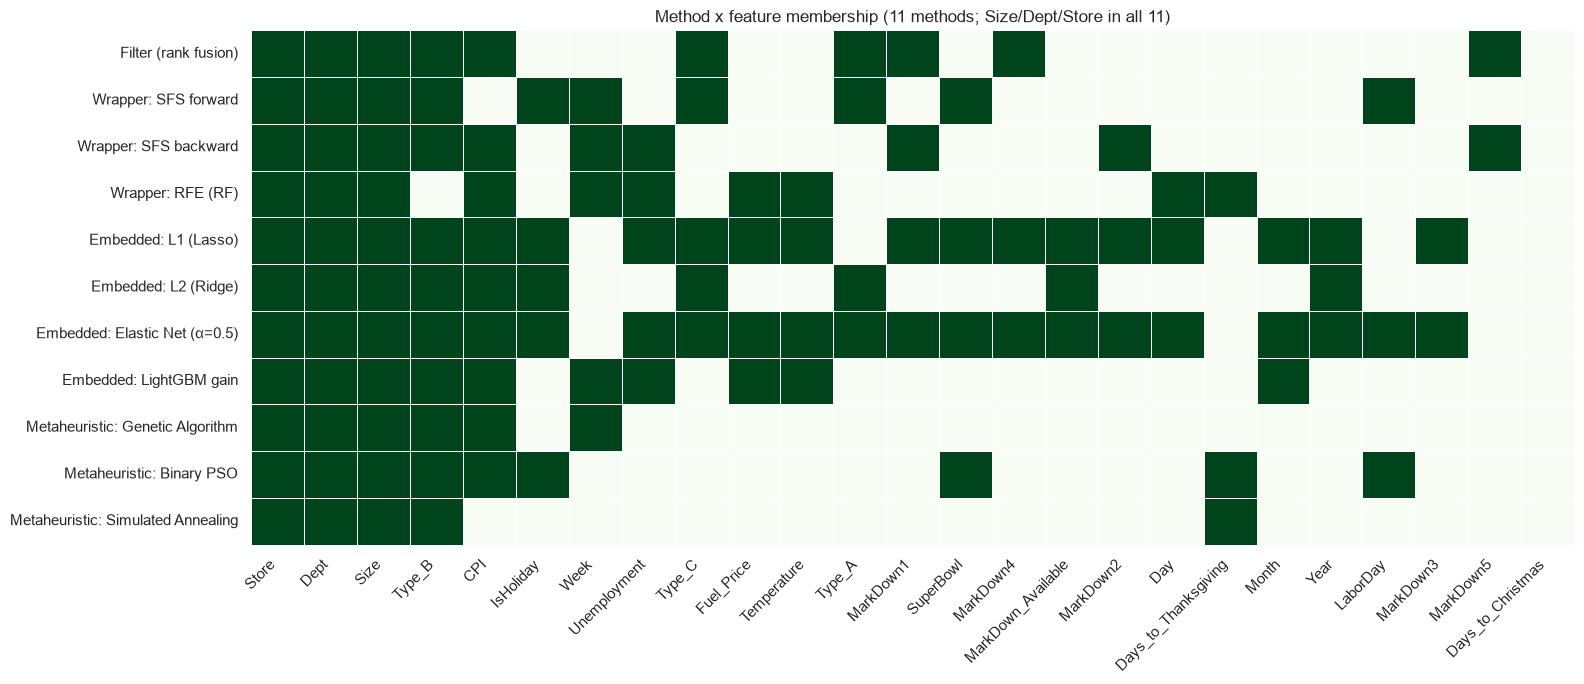

saved figures/phase1/23_selection_overlap.png


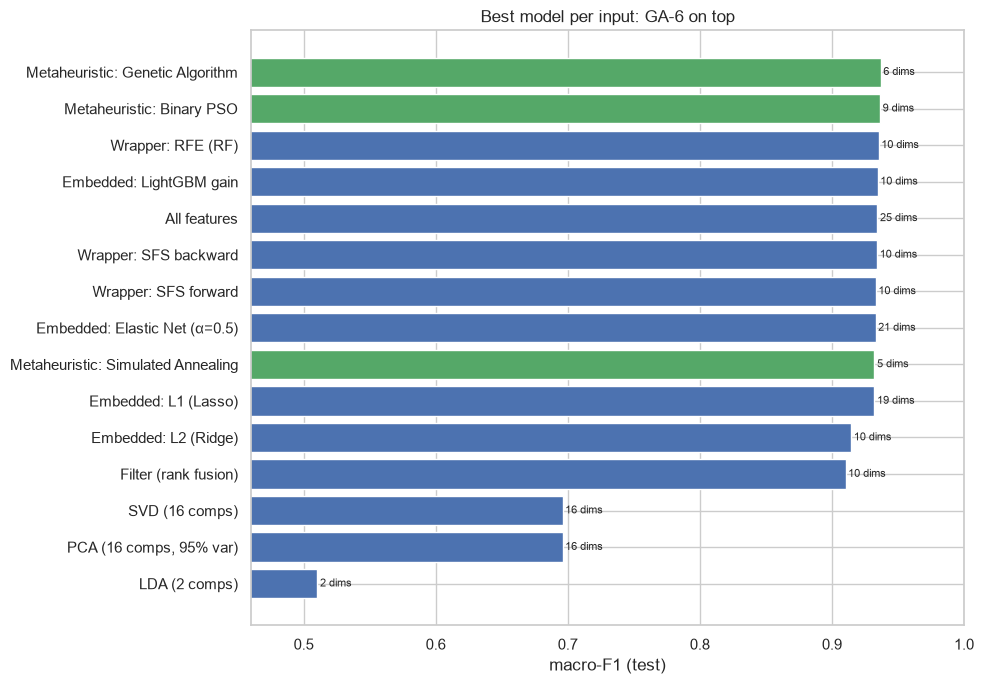

saved figures/phase1/23_f1_vs_dims.png


In [14]:
# 23 — Selection overlap (methods x features) + F1 vs #dims
methods = [m for m in subs.index if m != 'All features']
mat = pd.DataFrame(0, index=methods, columns=FEATURES)
for m in methods:
    for f in str(subs.loc[m, 'Features']).replace('(α=0.5)', '').split(','):
        f = f.strip()
        if f in mat.columns: mat.loc[m, f] = 1
order = mat.sum().sort_values(ascending=False).index

plt.figure(figsize=(16, 7))
sns.heatmap(mat[order], cmap='Greens', cbar=False, linewidths=0.5, linecolor='white')
plt.title(f'Method x feature membership ({len(methods)} methods; Size/Dept/Store in all {mat[["Size", "Dept", "Store"]].sum().min()})')
plt.xticks(rotation=45, ha='right')
savefig('23_selection_overlap')

s = subeval.sort_values('F1')
plt.figure(figsize=(10, 7))
cols = ['#55A868' if 'Metaheuristic' in i else '#4C72B0' for i in s.index]
b = plt.barh(s.index, s['F1'], color=cols)
for bar, d in zip(b, s['# dims']): plt.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2, f'{int(d)} dims', va='center', fontsize=8)
plt.xlim(s['F1'].min() - 0.05, 1); plt.xlabel('macro-F1 (test)'); plt.title('Best model per input: GA-6 on top')
savefig('23_f1_vs_dims')


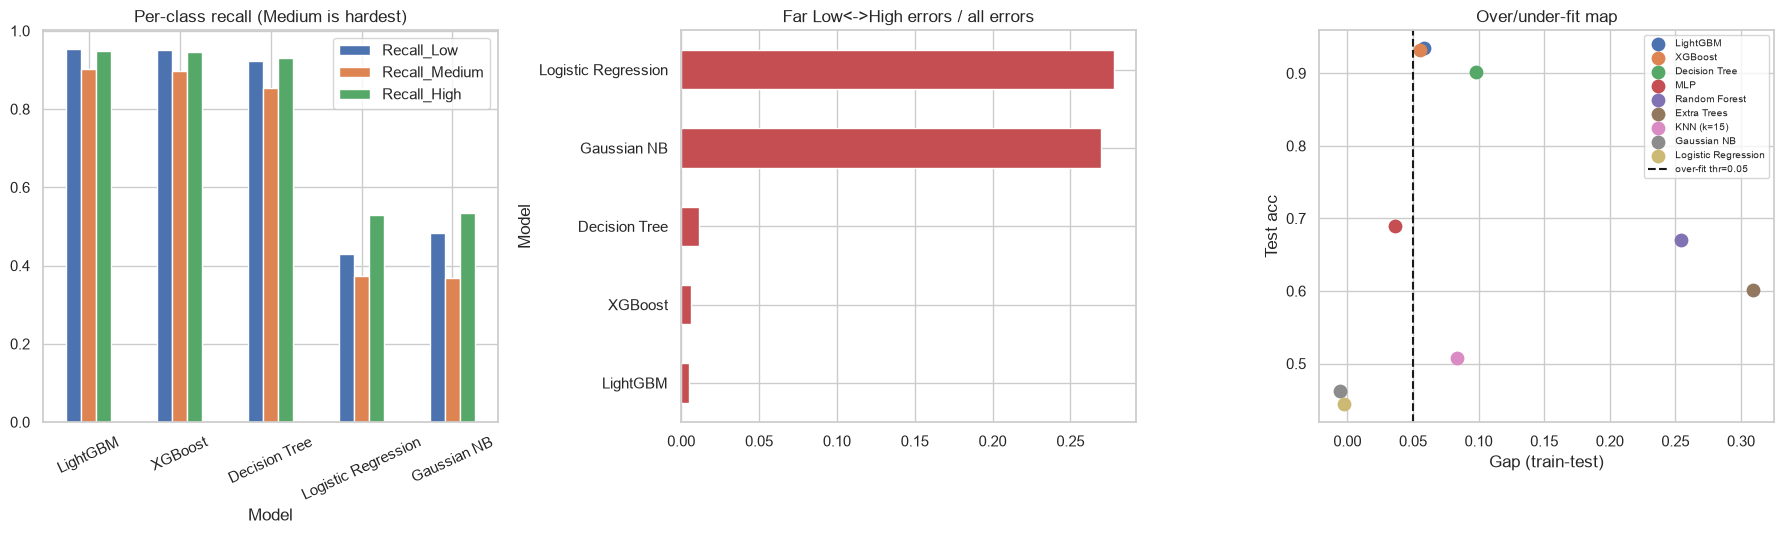

saved figures/phase1/24_error_analysis.png
['01_eda_overview.png', '02_correlation.png', '03_before_reduction.png', '04_pca_scree_loadings.png', '05_linear_embeddings.png', '06_all_embeddings.png', '07_clustering_before_after.png', '08_filter_scores.png', '09_embedded.png', '10_metaheuristic_convergence.png', '11_selection_frequency.png', '12_cv_boxplot.png', '13_confusion_matrices.png', '14_roc_curves.png', '15_over_under_fitting.png', '16_subset_comparison.png', '17_reduction_after_selection.png', '18_preprocessing_effect.png', '19_temporal_structure.png', '20_dept_store_dominance.png', '21_embedding_quality_summary.png', '22_cluster_composition.png', '22_cluster_quality_elbow.png', '23_f1_vs_dims.png', '23_selection_overlap.png', '24_error_analysis.png', '25_dataset_cartography.png', '26_missingness_deepdive.png', '27_sales_anatomy.png', '28_exogenous_relationships.png', '29_promotions.png', '30_calendar_windows.png']


In [15]:
# 24 — Error analysis: per-class recall, far-error share, acc-vs-gap
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
cmi[['Recall_Low', 'Recall_Medium', 'Recall_High']].plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452', '#55A868'])
ax[0].set_title('Per-class recall (Medium is hardest)')
ax[0].tick_params(axis='x', rotation=25)
cmi['Far_share'].sort_values().plot.barh(ax=ax[1], color='#C44E52')
ax[1].set_title('Far Low<->High errors / all errors')
for m, row in hold.iterrows():
    ax[2].scatter(row['Gap (train-test)'], row['Test acc'], s=80, label=m)
ax[2].axvline(0.05, ls='--', c='k', label='over-fit thr=0.05')
ax[2].set_xlabel('Gap (train-test)'); ax[2].set_ylabel('Test acc')
ax[2].set_title('Over/under-fit map'); ax[2].legend(fontsize=7)
savefig('24_error_analysis')
print(sorted(os.listdir(FIG)))
